<a href="https://colab.research.google.com/github/sallasaarinen/ibm-granite-dola/blob/main/DoLa_evaluation.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

**Evaluation of DoLa decoding**

This notebook evaluates the use of DoLa decoding together with the Granite-4.2-3B model on a small set of benchmark questions.

**1. Install requirements**

In [1]:
!pip install transformers
import matplotlib.pyplot as plt
import torch
from transformers import AutoModelForCausalLM, AutoTokenizer
import numpy as np
import matplotlib as mlp
from scipy.spatial import distance
import time

**2. Load the model**

Use Granite 4.2 3B

In [2]:


tokenizer = AutoTokenizer.from_pretrained("ibm-granite/granite-4.2-3b")
model = AutoModelForCausalLM.from_pretrained(
    "ibm-granite/granite-4.2-3b",
    dtype=torch.float16,
    device_map = "auto"
)

config.json:   0%|          | 0.00/905 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/17.7k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/7.15M [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/563 [00:00<?, ?B/s]

chat_template.jinja:   0%|          | 0.00/9.01k [00:00<?, ?B/s]

model.safetensors.index.json:   0%|          | 0.00/29.9k [00:00<?, ?B/s]

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 2 files:   0%|          | 0/2 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/363 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/207 [00:00<?, ?B/s]

**3. Check the outputs of different decoding methods**

In this step the model is used to generate outputs with three different decodings: standard, DoLa with dynamic layer choosing, and DoLa with static layer choosing. The results of each method are shown below.

In [3]:
inputs = tokenizer("The capital of the state of Washington is", return_tensors="pt")
outputs_dola= model.generate(
    **inputs,
    max_new_tokens=20,
    trust_remote_code=True,
    output_hidden_states=True,
    output_logits=True,
    do_sample=False,
    return_dict_in_generate = True,
    custom_generate="transformers-community/dola",
    dola_layers="high",
    repetition_penalty=1.2
)

outputs_standard= model.generate(
    **inputs,
    max_new_tokens=20,
    trust_remote_code=True,
    output_hidden_states=True,
    output_logits=True,
    do_sample=False,
    return_dict_in_generate = True,
    repetition_penalty=1.2
)

outputs_dola_static= model.generate(
    **inputs,
    max_new_tokens=20,
    trust_remote_code=True,
    output_hidden_states=True,
    output_logits=True,
    do_sample=False,
    return_dict_in_generate = True,
    custom_generate="transformers-community/dola",
    dola_layers=[3],
    repetition_penalty=1.2
)


generate.py:   0%|          | 0.00/18.2k [00:00<?, ?B/s]

[transformers] A new version of the following files was downloaded from https://huggingface.co/transformers-community/dola:
- custom_generate/generate.py
. Make sure to double-check they do not contain any added malicious code. To avoid downloading new versions of the code file, you can pin a revision.


In [4]:
print(tokenizer.decode(outputs_dola.sequences))
print(tokenizer.decode(outputs_dola_static.sequences))
print(tokenizer.decode(outputs_standard.sequences))

['The capital of the state of Washington is Olympia.\n\nWashington is a U.S. state located in the Pacific Northwest, bordered by']
['The capital of the state of Washington is Olympia. The state\'s nickname is "Evergreen State." Washington has a total area of 83']
['The capital of the state of Washington is Olympia. The population in 2022 was about 5,900,000 people."\n</think>']


**4. Begin the DoLa analysis**

In this step, a function is defined to analyse the outputs with both DoLa and standard decoding.

The function takes in the following parameters


*   Prompt: the prompt used for analysis
*   Model: The model used for this analysis
* Tokenizer: The tokenizer used to decode the model output into text
* Mode: default dola, can be changed to standard
* max_tokens: Maximum number of tokens the model can generate

The function returns top 4 candidates for the first generated tokens and their probabilities. The probability distributions for DoLa and standard decoding are plotted below.



In [5]:
def analyze_output(prompt, model, tokenizer, mode='dola', max_tokens=50):
  inputs = tokenizer(prompt, return_tensors="pt")
  #use dola decoding if mode=dola
  if mode=='dola':
    outputs= model.generate(
      **inputs,
      max_new_tokens=max_tokens,
      trust_remote_code=True,
      output_hidden_states=True,
      output_logits=True,
      output_scores=True,
      do_sample=False,
      return_dict_in_generate = True,
      custom_generate="transformers-community/dola",
      dola_layers="high",
      repetition_penalty=1.2
    )
  #if mode is not dola, use standard decoding
  else:

    outputs= model.generate(
        **inputs,
        max_new_tokens=max_tokens,
        trust_remote_code=True,
        output_hidden_states=True,
        output_logits=True,
        output_scores=True,
        do_sample=False,
        return_dict_in_generate = True,
        repetition_penalty=1.2
    )
  #calculate the probability distribution of the first generated token
  log_probs = torch.softmax(outputs.scores[0], dim=-1)
  #choose the top 4 candidate tokens
  top_probs, top_indices = torch.topk(log_probs, k=4)
  #return the probabilities and decoded tokens for the top 4 candidates
  return top_probs[0].tolist(), [tokenizer.decode(i) for i in top_indices[0].tolist()]


Text(0.5, 1.0, 'Candidate answers under standard decoding')

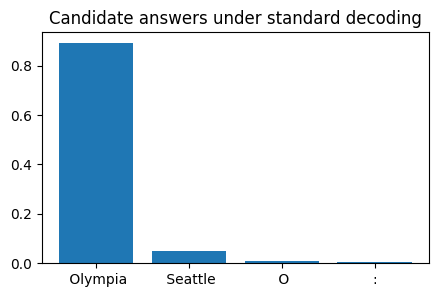

In [6]:
# analyse standard decoding results
probs_standard, tokens_standard = analyze_output("The capital of the state of Washington is", model, tokenizer, mode='standard')
plt.figure(figsize=(5,3))
plt.bar(tokens_standard, probs_standard)
plt.title("Candidate answers under standard decoding")

Text(0.5, 1.0, 'Candidate answers under DoLa decoding')

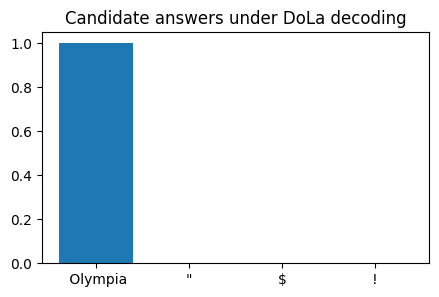

In [7]:
# analyse DoLa decoding results
probs_dola, tokens_dola = analyze_output("The capital of the state of Washington is", model, tokenizer, mode='dola')
plt.figure(figsize=(5,3))
plt.bar(tokens_dola, probs_dola)
plt.title("Candidate answers under DoLa decoding")

**5. Calculate and plot the JSD distribution**

This step analyses the changes in the probability distribution at each premature layer compared with the final layer. The metric used for this analysis is Jensen-Shannon divergence (JSD), which is calculated below.



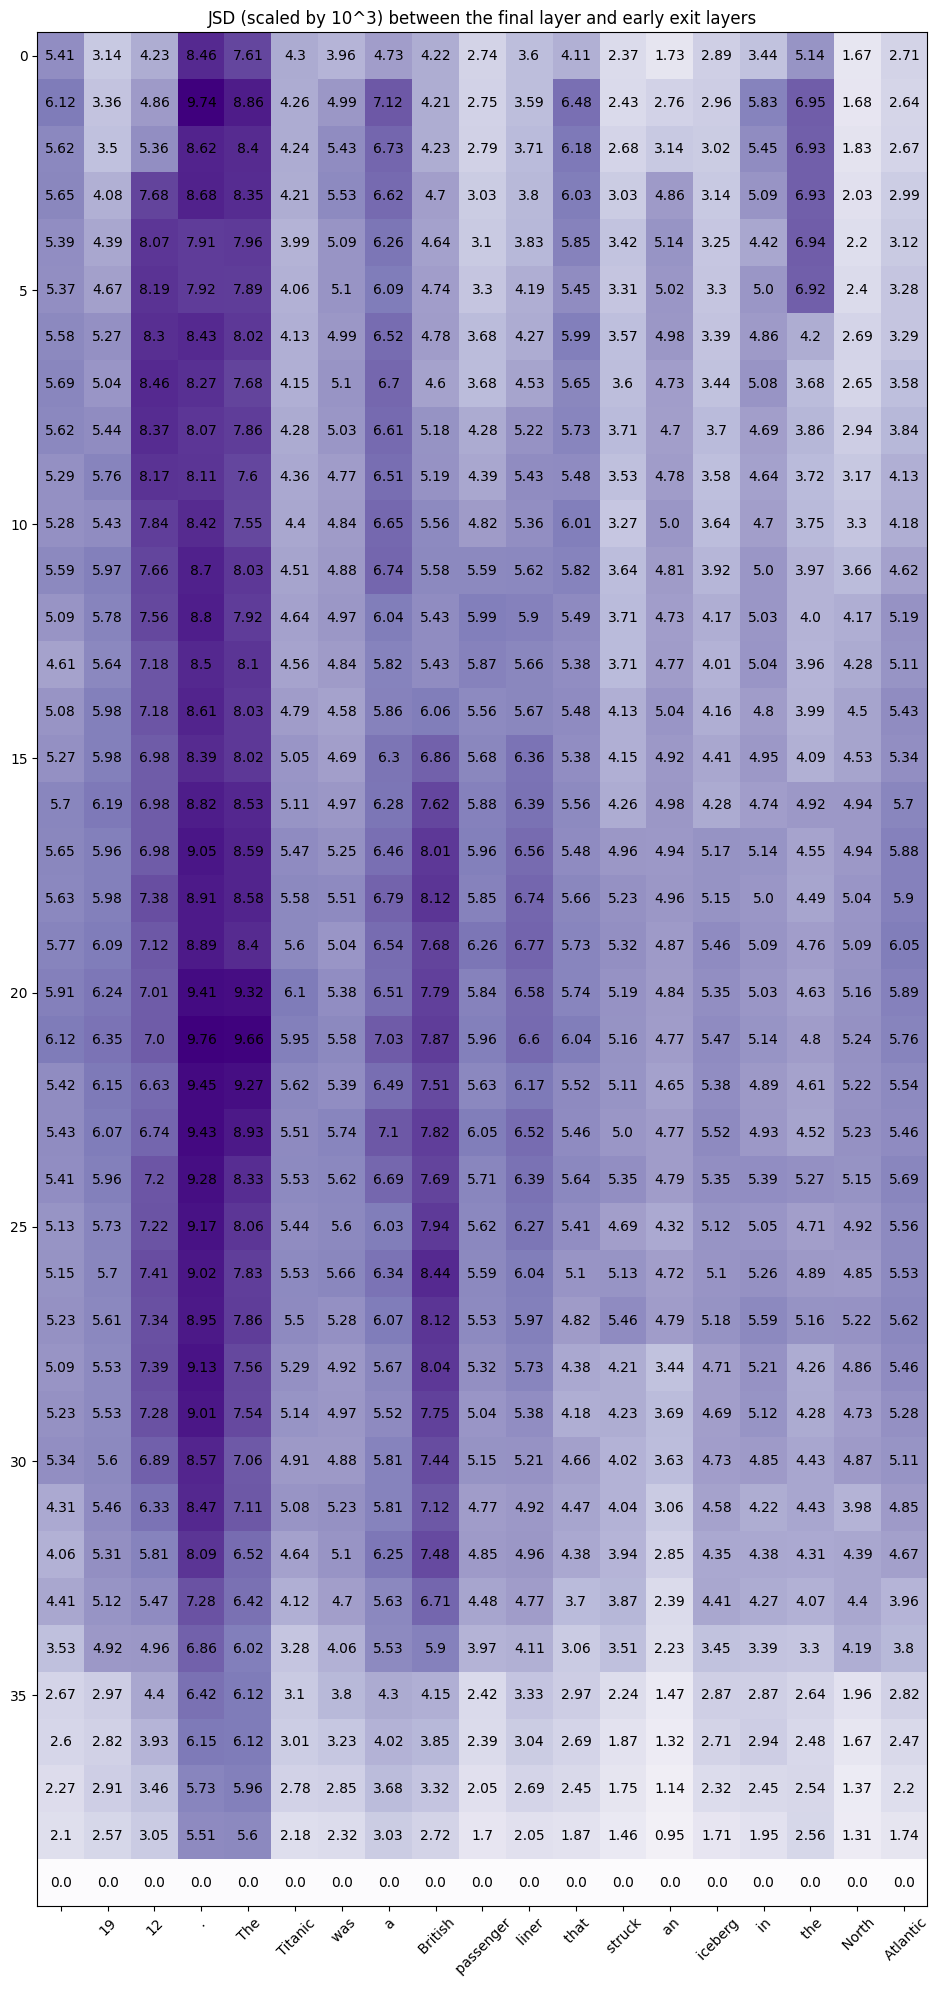

In [26]:
#Define the input prompt for the JSD analysis
inputs = tokenizer("The year when the Titanic sank is", return_tensors="pt")
#Generate outputs
outputs_jsd= model.generate(
    **inputs,
    max_new_tokens=20,
    trust_remote_code=True,
    output_hidden_states=True,
    output_logits=True,
    do_sample=False,
    return_dict_in_generate = True,
    custom_generate="transformers-community/dola",
    dola_layers="high",
    repetition_penalty=1.2
)
#All premature layer results are normalised to ensure similarity of probability distributions between premature and final layers
norm = model.model.norm
num_output_tokens = len(outputs_jsd.hidden_states)-1
num_layers = len(outputs_jsd.hidden_states[0])-1
#Create placeholder matrix for JSD values
jsd = [[0 for i in range(num_output_tokens)] for _ in range(num_layers)]
#Loop through each layer i
for i in range(1,num_layers+1):
  #Loop through each output token j
  for j in range(1,num_output_tokens+1):
    #Calculate probability distribution for the output token j at the final layer -1
    final_layer_probs = torch.log_softmax(model.lm_head(norm(outputs_jsd.hidden_states[j][-1]))[0][0], dim = -1)
    #Calculate probability distribution for the output token j at premature layer i
    current_layer_probs = torch.log_softmax(model.lm_head(norm(outputs_jsd.hidden_states[j][i]))[0][0], dim = -1)
    #Calculate Jensen-Shannon distance
    js_div = distance.jensenshannon(final_layer_probs.tolist(), current_layer_probs.tolist())
    #Calculate Jensen-Shannon divergence from distance
    js_dist = js_div**2
    #Scale the values by 10^3 and set the value to the matrix into position [layer-1][token-1]
    #Note: indexing starts from 0, so index 0 refers to layer 1 and output token 1 and so on
    jsd[i-1][j-1] = round(js_dist*1000,2)
fig, ax = plt.subplots(figsize=(10,20))
im = ax.imshow(jsd, cmap=mlp.colormaps['Purples'])


# Show all ticks and label them with the respective list entries
ax.set_xticks(range(num_output_tokens), labels=[str(tokenizer.decode(i)) for i in outputs_jsd.sequences[0]][len(inputs[0]):-1],
              rotation=45)

# Loop over data dimensions and create text annotations.
for i in range(num_layers):
    for j in range(num_output_tokens):
        text = ax.text(j, i, jsd[i][j],
                       ha="center", va="center", color="k")

ax.set_title("JSD (scaled by 10^3) between the final layer and early exit layers")
fig.tight_layout()
plt.show()

Check the top candidates for different tokens in premature layers

Text(0.5, 1.0, 'Candidate answers, premature layer')

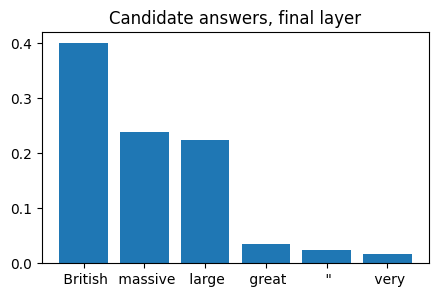

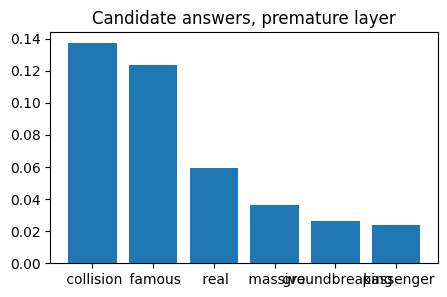

In [32]:
#Define the input prompt for the premature layer analysis
inputs = tokenizer("The year when the Titanic sank is", return_tensors="pt")
#Generate outputs
outputs_new= model.generate(
    **inputs,
    max_new_tokens=20,
    trust_remote_code=True,
    output_hidden_states=True,
    output_logits=True,
    do_sample=False,
    return_dict_in_generate = True,
    custom_generate="transformers-community/dola",
    dola_layers="high",
    repetition_penalty=1.2
)
final_layer_probs = torch.softmax(model.lm_head(norm(outputs_new.hidden_states[8][-1]))[0][0], dim = -1)
premature_layer_probs = torch.softmax(model.lm_head(norm(outputs_new.hidden_states[8][-7]))[0][0], dim = -1)

top_probs_final, top_indices_final = torch.topk(final_layer_probs, k=6)
top_probs_prem, top_indices_prem = torch.topk(premature_layer_probs, k=6)


plt.figure(figsize=(5,3))
plt.bar([tokenizer.decode(i) for i in top_indices_final.tolist()], top_probs_final.tolist())
plt.title("Candidate answers, final layer")

plt.figure(figsize=(5,3))
plt.bar([tokenizer.decode(i) for i in top_indices_prem.tolist()], top_probs_prem.tolist())
plt.title("Candidate answers, premature layer")



**6. Run the benchmark analysis**

In this step, a simple benchmark is set up and ran. The benchmark consists of four questions and it outputs the answer with both standard and DoLa decoding, and calculates the latency for both approaches. The function takes a list of the benchmark questions as input.

In [ ]:

#Define function for running benchmark analysis
def run_benchmark(benchmark_questions):
  benchmark_results = []
  #Loop through benchmark questions
  for i in benchmark_questions:
    print("Benchmark question: " + i + "\n")
    #Analyse DoLa decoding
    print("DoLa decoding")
    inputs = tokenizer(i, return_tensors="pt").to(model.device)
    #Begin timer for latency analysis
    start = time.perf_counter()
    #Generate output
    outputs_dola= model.generate(
      **inputs,
      max_new_tokens=200,
      trust_remote_code=True,
      do_sample=False,
      output_hidden_states=True,
      custom_generate="transformers-community/dola",
      dola_layers="high",
      repetition_penalty=1.2
    )
    #End timer for latency analysis and calculate time taken for generation
    end = time.perf_counter() - start
    #Print the outputs
    print(tokenizer.decode(outputs_dola))
    print('Latency: {:.6f} ms/token\n'.format(end/len(outputs_dola[0])*1000))

    #Analyse standard decoding
    print("Standard decoding")
    #Start timer for latency analysis
    start2 = time.perf_counter()
    #Generate outputs
    outputs_standard= model.generate(
      **inputs,
      max_new_tokens=200,
      trust_remote_code=True,
      do_sample=False,
      repetition_penalty=1.2
    )
    #End timer for latency analysis and calculate time taken for generation
    end2 = time.perf_counter() -start2
    #Print the outputs
    print(tokenizer.decode(outputs_standard))
    print('Latency: {:.6f} ms/token\n'.format(end2/len(outputs_standard[0])*1000))


In [ ]:
benchmark_questions = ["How many letters 'r' are in the word 'strawberry'?","When did Finland become independent?", "What is the original colour of the Statue of Liberty?", "Where was the Titanic built?"]
run_benchmark(benchmark_questions)

Benchmark question: How many letters 'r' are in the word 'strawberry'?

DoLa decoding
["How many letters 'r' are in the word 'strawberry'?\n\n<think></think>The word is: **strawberry**\n\nLet's count the letter 'r' (case-insensitive, but all letters are lowercase here).\n\nWrite out the word with positions:\n\ns t r a w b e r r y\n\nNow list each letter and check for 'r':\n\n1. s → no  \n2. t → no  \n3. r → yes (1)  \n4. a → no  \n5. w → no  \n6. b → no  \n7. e → no  \n8. r → yes (2)  \n9. r → yes (3)  \n10. y → no  \n\nSo we have 3 occurrences of the letter 'r'.\n\n✅ Answer: **3**<|im_end|>"]
Latency: 82.188785 ms/token

Standard decoding
['How many letters \'r\' are in the word \'strawberry\'?\n   - Count: s t r a w b e r y → two \'r\'s. Answer is 2.\n\n   **Answer:** There are \\boxed{2} letters \'r\'."\n\n We need to produce final answer accordingly, following instructions? The user gave an example of how they want output for that problem; but we have our own problems now (the ones